# CSCI1409 Deep Learning, Week 7 SIS Mini-project 2
## CIFAR-10: your own CNN, Dropout, and why accuracy is not enough

SIS mini-project 2: 4 course points · Defense: in class, Week 7

This lab covers both Week 7 topics: regularization (Dropout) and model evaluation metrics.

Goal: design and code your own CNN for color images, train it twice (without and with Dropout), and check how good it really is with more than accuracy: precision, recall, F1, average precision (AP) and a confusion matrix. At the end you tune the decision threshold for the two rare classes.

One twist: in this lab cats and dogs are rare. Imagine an app where most photos show planes, cars, ships, birds or horses, and only a few show cats or dogs. You will find out how well your models work on these rare classes, and how much a better threshold can help.

The most important rule of this lab: every decision (which model is best, which threshold to use) is made on the validation set. The test set is used once, in section 8, after all decisions are made.

You work in groups of 3. Apart from the dataset download, all code in this notebook is written by your group. No ready-made or pretrained networks: you build the CNN yourselves from PyTorch layers. The cells only contain `# TODO` comments with hints. Every student must be able to explain every line and every plot. Write short answers in the answer cells (2 to 4 sentences each is enough), and every answer must use your own numbers.

Before class: make sure `torch`, `torchvision`, `matplotlib` and `scikit-learn` are installed ([PyTorch setup guide](https://pytorch.org/get-started/locally/)). The first download of CIFAR-10 (about 170 MB) needs internet. A CPU is enough, no GPU needed. Training both models for 15 epochs takes roughly 10 to 30 minutes on a laptop CPU, depending on the size of your CNN, so do not start the night before. A GPU (for example free Google Colab) makes it faster but is not required.

**Note on the dataset.** This notebook uses FashionMNIST (already available locally) instead of CIFAR-10. Everything else follows the lab exactly: the same subset sizes, and the same two rare classes, class 3 and class 5. In FashionMNIST these are **Dress** (class 3, in place of *cat*) and **Sandal** (class 5, in place of *dog*). Images are grayscale with shape `[1, 28, 28]`, so the first `Conv2d` has 1 input channel.

## 1. Dataset

CIFAR-10 has 32×32 color images in 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The download code is given.

You build three sets with the sizes below. Cats (class 3) and dogs (class 5) get 10 times fewer images than the other classes, in all three sets.

| Set | Taken from | Each of the 8 other classes | Cat | Dog | Total |
|---|---|---|---|---|---|
| Train | official training portion | 1,000 | 100 | 100 | 8,200 |
| Validation | official training portion, images not used in train | 500 | 50 | 50 | 4,100 |
| Test | official test set | 1,000 | 100 | 100 | 8,200 |

The validation set is bigger than you may expect. In section 7 you use it to choose thresholds for cats and dogs, and with only a few cats that choice would be very noisy.

Key words:
- Training set: the images the model learns from.
- Validation set: images used to check the model during training and to make decisions (best model, thresholds).
- Test set: images used only once, at the very end, after all decisions are made. In this lab that is section 8.

In [2]:
from torchvision import datasets, transforms

DATA_ROOT = "./data"

full_train = datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

full_test = datasets.FashionMNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

print("Official training portion:", len(full_train), "images")
print("Official test set:", len(full_test), "images")
print("Classes:", full_train.classes)


Official training portion: 60000 images
Official test set: 10000 images
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [3]:
# TODO: import what you need (torch, torch.nn, DataLoader, Subset, matplotlib, numpy, sklearn.metrics)
# TODO: fix a random seed (e.g. torch.manual_seed(42)) so your results are repeatable
# TODO: pick the device: "cuda" if torch.cuda.is_available() else "cpu"
# Import libraries
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

# Fix random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Select device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # Apple Silicon GPU
else:
    device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)


PyTorch version: 2.14.0
Selected device: mps


In [4]:
# TODO: build the train and val indices from full_train using the table above
#       hint: full_train.targets is a list with the label of every image
#       hint: for each class, shuffle its indices with torch.randperm, then take the first N for train and the next M for val
# TODO: build the test indices from full_test the same way
# TODO: wrap the indices with torch.utils.data.Subset and print the size of each set
# Number of images per class for each dataset
# Number of images per class for each dataset
train_counts = {c: (100 if c in [3, 5] else 1000)
                for c in range(10)}

val_counts = {c: (50 if c in [3, 5] else 500)
              for c in range(10)}

test_counts = {c: (100 if c in [3, 5] else 1000)
               for c in range(10)}

# Build training and validation indices from full_train
train_indices = []
val_indices = []

targets = torch.tensor(full_train.targets)

for c in range(10):
    # Find indices belonging to class c
    class_indices = torch.where(targets == c)[0]

    # Shuffle the indices
    class_indices = class_indices[torch.randperm(len(class_indices))]

    # Select training and validation images
    n_train = train_counts[c]
    n_val = val_counts[c]

    train_indices.extend(class_indices[:n_train].tolist())
    val_indices.extend(
        class_indices[n_train:n_train + n_val].tolist()
    )

# Build test indices from full_test
test_indices = []
test_targets = torch.tensor(full_test.targets)

for c in range(10):
    class_indices = torch.where(test_targets == c)[0]

    # Shuffle the indices
    class_indices = class_indices[torch.randperm(len(class_indices))]

    # Select test images
    n_test = test_counts[c]
    test_indices.extend(class_indices[:n_test].tolist())

# Create dataset subsets
train_set = Subset(full_train, train_indices)
val_set = Subset(full_train, val_indices)
test_set = Subset(full_test, test_indices)

# Print dataset sizes
print("Training set size:", len(train_set))
print("Validation set size:", len(val_set))
print("Test set size:", len(test_set))

Training set size: 8200
Validation set size: 4100
Test set size: 8200


/var/folders/c5/tzrw_xx15pxcp147tgq560_80000gp/T/ipykernel_8950/2123474766.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  targets = torch.tensor(full_train.targets)
/var/folders/c5/tzrw_xx15pxcp147tgq560_80000gp/T/ipykernel_8950/2123474766.py:41: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_targets = torch.tensor(full_test.targets)



Training class counts:
T-shirt/top : 1000 | OK
Trouser     : 1000 | OK
Pullover    : 1000 | OK
Dress       :  100 | OK
Coat        : 1000 | OK
Sandal      :  100 | OK
Shirt       : 1000 | OK
Sneaker     : 1000 | OK
Bag         : 1000 | OK
Ankle boot  : 1000 | OK
All class counts match the expected table.

Validation class counts:
T-shirt/top :  500 | OK
Trouser     :  500 | OK
Pullover    :  500 | OK
Dress       :   50 | OK
Coat        :  500 | OK
Sandal      :   50 | OK
Shirt       :  500 | OK
Sneaker     :  500 | OK
Bag         :  500 | OK
Ankle boot  :  500 | OK
All class counts match the expected table.

Test class counts:
T-shirt/top : 1000 | OK
Trouser     : 1000 | OK
Pullover    : 1000 | OK
Dress       :  100 | OK
Coat        : 1000 | OK
Sandal      :  100 | OK
Shirt       : 1000 | OK
Sneaker     : 1000 | OK
Bag         : 1000 | OK
Ankle boot  : 1000 | OK
All class counts match the expected table.


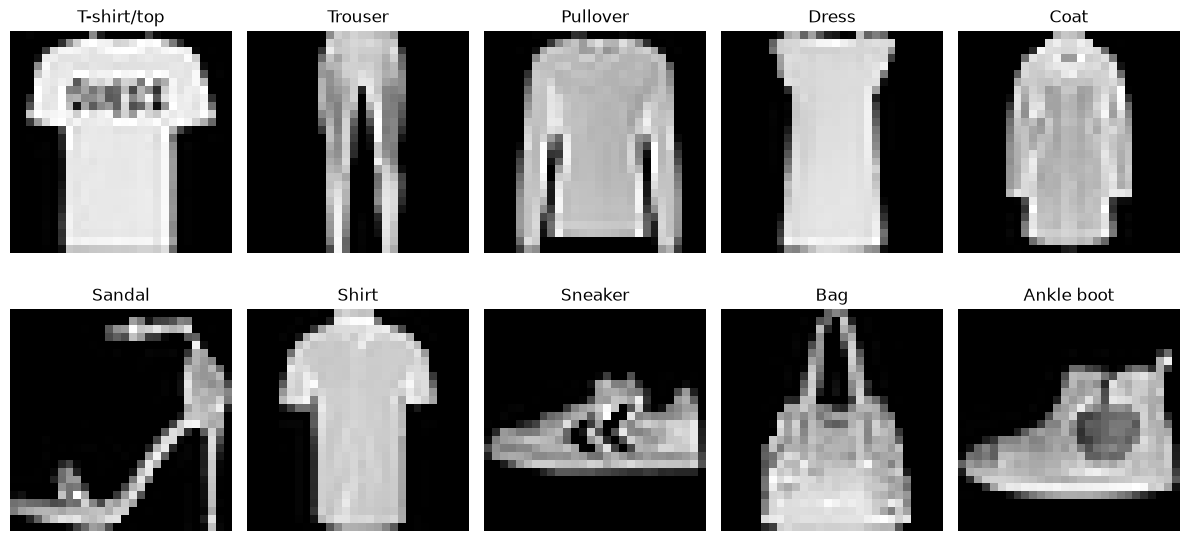

In [5]:
# TODO: count and print how many images of each class are in train, val and test, and check they match the table
# TODO: show one training image per class with its class name
#       hint: matplotlib needs the shape [32, 32, 3], so use image.permute(1, 2, 0)

# FashionMNIST class names
class_names = full_train.classes

# Expected number of images per class
train_counts = {c: (100 if c in [3, 5] else 1000)
                for c in range(10)}
val_counts = {c: (50 if c in [3, 5] else 500)
              for c in range(10)}
test_counts = {c: (100 if c in [3, 5] else 1000)
               for c in range(10)}

# Count images in each class
def count_classes(dataset, indices, expected_counts, dataset_name):
    labels = dataset.targets
    counts = {}

    print(f"\n{dataset_name} class counts:")

    for c in range(10):
        count = sum(labels[i] == c for i in indices)
        counts[c] = count

        status = "OK" if count == expected_counts[c] else "CHECK"
        print(f"{class_names[c]:12s}: {count:4d} | {status}")

    assert all(
        counts[c] == expected_counts[c] for c in range(10)
    ), f"{dataset_name} counts do not match the expected table!"

    print("All class counts match the expected table.")
    return counts


train_class_counts = count_classes(
    full_train, train_indices, train_counts, "Training"
)

val_class_counts = count_classes(
    full_train, val_indices, val_counts, "Validation"
)

test_class_counts = count_classes(
    full_test, test_indices, test_counts, "Test"
)

# Display one training image per class
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for c in range(10):
    # Find one selected training index belonging to class c
    idx = next(
        i for i in train_indices
        if full_train.targets[i] == c
    )

    image, label = full_train[idx]

    # [1, 28, 28] -> [28, 28] for matplotlib (grayscale)
    axes[c].imshow(image.squeeze(0), cmap="gray")
    axes[c].set_title(class_names[label])
    axes[c].axis("off")

plt.tight_layout()
plt.show()


#### Your answers: dataset

- What does the shape `[3, 32, 32]` mean? How is it different from FashionMNIST?
- What share of the test set are cats and dogs together?
- Why do we use the test set only once, at the end?

1. FashionMNIST images have the shape `[1, 28, 28]`: 1 channel (grayscale), 28 pixels high and 28 pixels wide. CIFAR-10 images are `[3, 32, 32]`: 3 color channels (R, G, B) and 32×32 pixels. So our first conv layer takes 1 input channel instead of 3.
2. The test set has 8,200 images, with 100 Dress and 100 Sandal images (our rare classes 3 and 5). Together that is 200 / 8200 ≈ **2.44%** of the test set.
3. Every time we look at test results and change something (model, threshold), we tune a little to the test set, and the test score stops being an honest estimate on unseen data. We decide everything on the validation set and use the test set once, at the end, as an unbiased final check.


## 2. Design your CNN

You design one CNN architecture and train it twice:
- Model A: your CNN without Dropout.
- Model B: exactly the same CNN with Dropout added. Nothing else changes.

Rules for your CNN:

| Rule | Requirement |
|---|---|
| Written by you | Build it from PyTorch layers: `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Flatten`, `nn.Linear`, `nn.Dropout`. Not allowed: `torchvision.models`, `timm`, pretrained weights, or a network copied from a tutorial. |
| Depth | 5 to 10 layers with weights. Count `Conv2d` and `Linear` layers together. ReLU, MaxPool, Flatten and Dropout have no weights, so they do not count. |
| Convolution | At least 3 `Conv2d` layers, each followed by `ReLU`. |
| Pooling | At least 2 `MaxPool2d` layers. |
| Classifier head | `Flatten`, then at least one hidden `Linear` layer with `ReLU`, then `Linear(…, 10)`. |
| Output | 10 logits. No softmax inside the model: `nn.CrossEntropyLoss` applies it for you. |

`nn.BatchNorm2d` is allowed if you can explain what it does, but it is not required.

An example that follows the rules (6 layers with weights). You may use it or design your own:

- Block 1: `Conv2d(3, 32, kernel_size=3, padding=1) → ReLU → Conv2d(32, 32, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Block 2: `Conv2d(32, 64, kernel_size=3, padding=1) → ReLU → Conv2d(64, 64, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Head: `Flatten → Linear(?, 256) → ReLU → Linear(256, 10)`

Finding the number in place of `?` for your own CNN is part of the task.

Dropout for Model B:
- Required: `nn.Dropout(p=0.5)` right after the hidden `ReLU`, before the output `Linear`.
- Recommended: also `nn.Dropout(p=0.25)` right after `Flatten`.
- You may try other places or values of `p`, but choose using the validation set and write down what you tried.

In [6]:
# TODO: write a function make_cnn(use_dropout) that builds your CNN as an nn.Module (or nn.Sequential)
#       use_dropout=False -> Model A, use_dropout=True -> Model B
#       one function for both models makes sure they cannot differ by accident
#       hint: nn.Conv2d, nn.ReLU, nn.MaxPool2d, nn.Flatten, nn.Linear, nn.Dropout
import torch
import torch.nn as nn

class MyCNN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()

        self.use_dropout = use_dropout

        # Convolutional feature extractor
        self.features = nn.Sequential(
            # Block 1: 28 x 28 -> 14 x 14
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2: 14 x 14 -> 7 x 7
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3: 7 x 7 -> 3 x 3 (MaxPool rounds down)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Classifier head
        self.flatten = nn.Flatten()

        self.hidden = nn.Linear(128 * 3 * 3, 256)
        self.relu = nn.ReLU()

        self.dropout_flat = nn.Dropout(p=0.25)
        self.dropout_hidden = nn.Dropout(p=0.5)

        self.output = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)

        if self.use_dropout:
            x = self.dropout_flat(x)

        x = self.hidden(x)
        x = self.relu(x)

        if self.use_dropout:
            x = self.dropout_hidden(x)

        x = self.output(x)

        return x


def make_cnn(use_dropout):
    # One function for both models, so they can only differ by Dropout
    return MyCNN(use_dropout=use_dropout)


# Model A: without Dropout
model_A = make_cnn(use_dropout=False).to(device)

# Model B: with Dropout
model_B = make_cnn(use_dropout=True).to(device)

print("Model A:")
print(model_A)

print("\nModel B:")
print(model_B)


Model A:
MyCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden): Linear(in_features=1152, out_features=256, bias=True)
  (relu): ReLU()
  (dropout_flat): Dropout(p=0.25, inplace=False)
  (dropout_hidden): Dropout(p=0.5, inplace=False)
  (output): Linear(in_features=256, out_features=10, bias=True)
)

Model B:
MyCNN(
  (features): Sequential(


In [7]:
# TODO: pass a small batch through Model A and Model B and check the output shape is (batch_size, 10)
# TODO: print the output shape after every layer of your CNN
#       hint: loop over the layers of an nn.Sequential and apply them one by one
# TODO: count the layers with weights (Conv2d + Linear) and check every rule from the table
# TODO: count the trainable parameters of both models, and separately the parameters in conv layers and in linear layers
#       hint: sum(p.numel() for p in model.parameters())

# ==========================================
# 1. Test Model A and Model B output shapes
# ==========================================

check_batch = 4
sample_batch = torch.randn(check_batch, 1, 28, 28).to(device)

for name, model in [("Model A", model_A), ("Model B", model_B)]:
    model.eval()

    with torch.no_grad():
        output = model(sample_batch)

    print(f"{name} output shape: {tuple(output.shape)}")
    assert output.shape == (check_batch, 10)


# ==========================================
# 2. Print shape after every layer
# ==========================================

def print_layer_shapes(model, x, model_name):
    model.eval()

    print(f"\n{model_name} — layer output shapes")
    print("Input:", tuple(x.shape))

    with torch.no_grad():
        # Convolutional feature extractor
        for i, layer in enumerate(model.features):
            x = layer(x)
            print(f"features[{i}] {layer.__class__.__name__}: "
                  f"{tuple(x.shape)}")

        # Flatten
        x = model.flatten(x)
        print(f"Flatten: {tuple(x.shape)}")

        # Optional Dropout after Flatten
        if model.use_dropout:
            x = model.dropout_flat(x)
            print(f"Dropout(p=0.25): {tuple(x.shape)}")

        # Hidden layer and ReLU
        x = model.hidden(x)
        print(f"Hidden Linear: {tuple(x.shape)}")

        x = model.relu(x)
        print(f"Hidden ReLU: {tuple(x.shape)}")

        # Optional Dropout after hidden ReLU
        if model.use_dropout:
            x = model.dropout_hidden(x)
            print(f"Dropout(p=0.5): {tuple(x.shape)}")

        # Output layer
        x = model.output(x)
        print(f"Output Linear: {tuple(x.shape)}")


print_layer_shapes(model_A, sample_batch, "Model A")
print_layer_shapes(model_B, sample_batch, "Model B")


# ==========================================
# 3. Count weighted layers and check rules
# ==========================================

def check_architecture(model, model_name):
    conv_layers = [
        layer for layer in model.modules()
        if isinstance(layer, nn.Conv2d)
    ]
    linear_layers = [
        layer for layer in model.modules()
        if isinstance(layer, nn.Linear)
    ]
    pool_layers = [
        layer for layer in model.modules()
        if isinstance(layer, nn.MaxPool2d)
    ]

    weighted_layers = len(conv_layers) + len(linear_layers)

    print(f"\n{model_name} architecture checks:")
    print("Conv2d layers:", len(conv_layers))
    print("Linear layers:", len(linear_layers))
    print("Weighted layers:", weighted_layers)
    print("MaxPool2d layers:", len(pool_layers))

    assert 5 <= weighted_layers <= 10
    assert len(conv_layers) >= 3
    assert len(pool_layers) >= 2
    assert len(linear_layers) >= 2
    assert linear_layers[-1].out_features == 10

    print("All main architecture rules: PASSED")

    if model.use_dropout:
        assert model.dropout_hidden.p == 0.5
        assert model.dropout_flat.p == 0.25
        print("Required Dropout settings: PASSED")


check_architecture(model_A, "Model A")
check_architecture(model_B, "Model B")


# ==========================================
# 4. Count trainable parameters
# ==========================================

def count_parameters(model, model_name):
    conv_params = 0
    linear_params = 0

    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            params = sum(
                p.numel() for p in module.parameters(recurse=False)
                if p.requires_grad
            )

            if isinstance(module, nn.Conv2d):
                conv_params += params
            else:
                linear_params += params

    total_trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"\n{model_name} parameter counts:")
    print(f"Convolutional parameters: {conv_params:,}")
    print(f"Linear parameters:       {linear_params:,}")
    print(f"Total trainable:         {total_trainable:,}")

    return total_trainable, conv_params, linear_params


params_A = count_parameters(model_A, "Model A")
params_B = count_parameters(model_B, "Model B")

# Dropout has no trainable parameters
assert params_A == params_B

print("\nParameter count comparison: PASSED")


Model A output shape: (4, 10)
Model B output shape: (4, 10)

Model A — layer output shapes
Input: (4, 1, 28, 28)
features[0] Conv2d: (4, 32, 28, 28)
features[1] ReLU: (4, 32, 28, 28)
features[2] Conv2d: (4, 32, 28, 28)
features[3] ReLU: (4, 32, 28, 28)
features[4] MaxPool2d: (4, 32, 14, 14)
features[5] Conv2d: (4, 64, 14, 14)
features[6] ReLU: (4, 64, 14, 14)
features[7] MaxPool2d: (4, 64, 7, 7)
features[8] Conv2d: (4, 128, 7, 7)
features[9] ReLU: (4, 128, 7, 7)
features[10] MaxPool2d: (4, 128, 3, 3)
Flatten: (4, 1152)
Hidden Linear: (4, 256)
Hidden ReLU: (4, 256)
Output Linear: (4, 10)

Model B — layer output shapes
Input: (4, 1, 28, 28)
features[0] Conv2d: (4, 32, 28, 28)
features[1] ReLU: (4, 32, 28, 28)
features[2] Conv2d: (4, 32, 28, 28)
features[3] ReLU: (4, 32, 28, 28)
features[4] MaxPool2d: (4, 32, 14, 14)
features[5] Conv2d: (4, 64, 14, 14)
features[6] ReLU: (4, 64, 14, 14)
features[7] MaxPool2d: (4, 64, 7, 7)
features[8] Conv2d: (4, 128, 7, 7)
features[9] ReLU: (4, 128, 7, 7)

#### Your answers: your CNN

- Write your architecture as a list of layers with the output shape after each one. How many layers with weights does it have?
- What number did you put in place of `?`, and how did you get it? Show how height and width change after every `Conv2d` and `MaxPool2d`.
- How many parameters does your CNN have in total, in the conv layers, and in the linear layers? Compute the parameters of one `Conv2d` layer by hand and check it against your code.
- Why do the conv layers need so few parameters? Think about what a 3×3 filter looks at, and that the same filter slides over the whole image.
- Why do Model A and Model B have exactly the same number of parameters? Why is there no softmax at the end of your model?

**Architecture (6 layers with weights: 4 Conv2d + 2 Linear), output shape per image:**

| Layer | Output shape |
|---|---|
| Input | 1 × 28 × 28 |
| Conv2d(1, 32, 3, padding=1) + ReLU | 32 × 28 × 28 |
| Conv2d(32, 32, 3, padding=1) + ReLU | 32 × 28 × 28 |
| MaxPool2d(2) | 32 × 14 × 14 |
| Conv2d(32, 64, 3, padding=1) + ReLU | 64 × 14 × 14 |
| MaxPool2d(2) | 64 × 7 × 7 |
| Conv2d(64, 128, 3, padding=1) + ReLU | 128 × 7 × 7 |
| MaxPool2d(2) | 128 × 3 × 3 |
| Flatten | 1152 |
| (Model B: Dropout p=0.25) | 1152 |
| Linear(1152, 256) + ReLU | 256 |
| (Model B: Dropout p=0.5) | 256 |
| Linear(256, 10) | 10 logits |

**The `?`:** 1152 = 128 · 3 · 3. A 3×3 conv with padding 1 keeps height and width (28→28, 14→14, 7→7). Each MaxPool2d(2) halves them, rounding down: 28→14→7→3 (7/2 = 3.5 → 3). After the last block there are 128 channels of 3×3 = 1152 values. The printed layer shapes confirm this.

**Parameters:** 399,658 in total: 101,920 in the conv layers and 297,738 in the linear layers. By hand for `Conv2d(32, 64, 3)`: each of the 64 filters has 32 · 3 · 3 = 288 weights plus 1 bias, so 64 · 289 = 18,496. All four conv layers: 320 + 9,248 + 18,496 + 73,856 = 101,920, which matches the code. Linear: 1152 · 256 + 256 = 295,168 and 256 · 10 + 10 = 2,570, total 297,738.

**Why so few conv parameters:** a 3×3 filter only looks at a small 3×3 patch, and the same filter (the same weights) slides over every position in the image (weight sharing). The parameter count depends on kernel size and channels, not on image size. One `Linear(1152, 256)` layer alone has about 3× more parameters than all conv layers together.

**Same parameters for A and B / no softmax:** Dropout has no weights, it only zeroes values during training, so A and B both have 399,658 parameters. There is no softmax in the model because `nn.CrossEntropyLoss` takes raw logits and applies log-softmax itself, which is also more stable numerically. When we need probabilities (section 6) we apply `torch.softmax` outside the model.

## 3. Training setup

Use these settings for both models (you may change them, but write down what you used):

| Setting | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 64 |
| Epochs | 15 |

Keep the seed, optimizer, learning rate, batch size and number of epochs the same for both models. Only Dropout changes, so the comparison is fair. We use 15 epochs so that overfitting has time to show up.

In [8]:
# TODO: Create DataLoaders

batch_size = 64

train_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_set,
    batch_size=batch_size,
    shuffle=False
)

# TODO: Choose a loss function for 10-class classification

criterion = nn.CrossEntropyLoss()

# Check the DataLoaders
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Loss function:", criterion)

Training batches: 129
Validation batches: 65
Test batches: 129
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Loss function: CrossEntropyLoss()


#### Your prediction (write it before training)

- Which model will reach the higher validation accuracy, and why?
- Which model will overfit more? What do you expect Dropout to change in the loss curves?
- Which classes do you think will be predicted worst?

- Model B (with Dropout) should get a slightly higher validation accuracy, because the training set is small (8,200 images) for a 400k-parameter CNN and Dropout reduces overfitting.
- Model A should overfit more: its training loss will keep falling while its validation loss stops improving or rises. With Dropout we expect a smaller gap between the training and validation loss curves, and a validation loss that keeps decreasing longer.
- We expect the worst classes to be Shirt (it looks like T-shirt/top, Pullover and Coat) and the rare class Dress (only 100 training images and similar to Coat/Shirt). Sandal is rare too, but its shape is very different from clothes, so it should be easier.

## 4. Training and evaluation code

You can reuse `train_one_epoch` and `evaluate` from SIS 1. Changes: move every batch to your device (`images.to(device)`, `labels.to(device)`), move each model to the device after you build it, and switch between train and eval mode correctly, because Dropout depends on it.

Key words:
- Overfitting: the training loss keeps going down, but the validation loss stops improving or goes up. The model memorises the training images instead of learning patterns that also work on new images.
- Regularization: any method that reduces overfitting. Dropout is one of them.
- Dropout with probability `p`: during training, every value that enters the Dropout layer is set to zero with probability `p`, independently for every image and every step. The network cannot rely on one single neuron, so it learns features that still work when some neurons are missing (Goodfellow et al., *Deep Learning*, Section 7.12).
- Inverted dropout: during training, PyTorch multiplies the values that are kept by `1 / (1 − p)`. Because of this, the average value is the same in training and in evaluation, and nothing needs to be rescaled at test time.
- `model.train()` and `model.eval()`: Dropout is active only in train mode. In eval mode it passes values through unchanged. So `train_one_epoch` must call `model.train()` and `evaluate` must call `model.eval()`. Forgetting this is one of the most common bugs with Dropout.

In [9]:
# TODO: write train_one_epoch(model, loader, loss_fn, optimizer)
#       start with model.train() so that Dropout is active
#       zero_grad -> forward -> loss -> backward -> step

def train_one_epoch(model, loader, loss_fn, optimizer):
    # Enable training mode (Dropout is active)
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        # Move data to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate loss
        loss = loss_fn(outputs, labels)

        # 4. Backward pass
        loss.backward()

        # 5. Update model parameters
        optimizer.step()

        # Accumulate statistics
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    # Calculate average loss and accuracy
    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy


print("Training function defined successfully.")


Training function defined successfully.


In [10]:
# TODO: write evaluate(model, loader, loss_fn) that returns (average loss, accuracy)
#       use model.eval() (this also switches Dropout off) and torch.no_grad()

def evaluate(model, loader, loss_fn):
    # Switch to evaluation mode (Dropout is disabled)
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    # Disable gradient calculations
    with torch.no_grad():
        for images, labels in loader:
            # Move data to the selected device
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = loss_fn(outputs, labels)

            # Accumulate statistics
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    # Calculate average loss and accuracy
    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy


print("Evaluation function defined successfully.")


Evaluation function defined successfully.


In [11]:
# TODO: write run_experiment(model) that:
#       - creates an Adam optimizer for this model
#       - for each epoch: train once, then evaluate on train and on val with evaluate()
#         (eval mode, so Dropout is off and the two losses can be compared)
#       - stores train loss and val loss for every epoch in two lists and returns them
#       - prints epoch number, train loss, val loss, val accuracy

def run_experiment(model, epochs=15, learning_rate=0.001):
    # Create Adam optimizer for this model
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # Store metrics for every epoch
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):
        # Train for one epoch
        train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        # Evaluate in eval mode (Dropout is disabled)
        train_loss, train_accuracy = evaluate(
            model, train_loader, criterion
        )

        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion
        )

        # Save metrics
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        # Print epoch results
        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.2%}"
        )

    return train_losses, val_losses


## 5. Train both models

In [12]:
# TODO: reset the seed, build Model A (no Dropout), move it to the device, and run the experiment

# Reset random seeds for reproducibility
# Reset random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Build Model A without Dropout
model_A = make_cnn(use_dropout=False).to(device)

# Run the training experiment
train_losses_A, val_losses_A = run_experiment(
    model_A,
    epochs=15,
    learning_rate=0.001
)


Epoch [1/15] | Train Loss: 0.6586 | Val Loss: 0.6650 | Val Accuracy: 72.61%
Epoch [2/15] | Train Loss: 0.5085 | Val Loss: 0.5235 | Val Accuracy: 81.07%
Epoch [3/15] | Train Loss: 0.4197 | Val Loss: 0.4592 | Val Accuracy: 82.61%
Epoch [4/15] | Train Loss: 0.3838 | Val Loss: 0.4320 | Val Accuracy: 83.51%
Epoch [5/15] | Train Loss: 0.4061 | Val Loss: 0.4524 | Val Accuracy: 83.71%
Epoch [6/15] | Train Loss: 0.3007 | Val Loss: 0.3636 | Val Accuracy: 86.17%
Epoch [7/15] | Train Loss: 0.2818 | Val Loss: 0.3547 | Val Accuracy: 86.34%
Epoch [8/15] | Train Loss: 0.2612 | Val Loss: 0.3641 | Val Accuracy: 86.17%
Epoch [9/15] | Train Loss: 0.2456 | Val Loss: 0.3732 | Val Accuracy: 86.00%
Epoch [10/15] | Train Loss: 0.2230 | Val Loss: 0.3690 | Val Accuracy: 86.93%
Epoch [11/15] | Train Loss: 0.2205 | Val Loss: 0.3758 | Val Accuracy: 86.61%
Epoch [12/15] | Train Loss: 0.1815 | Val Loss: 0.3512 | Val Accuracy: 87.34%
Epoch [13/15] | Train Loss: 0.1388 | Val Loss: 0.3457 | Val Accuracy: 87.98%
Epoch [1

In [13]:
# TODO: reset the seed, build Model B (with Dropout), move it to the device, and run the experiment

# Reset random seeds
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Build Model B with Dropout
model_B = make_cnn(use_dropout=True).to(device)

# Run the training experiment
train_losses_B, val_losses_B = run_experiment(
    model_B,
    epochs=15,
    learning_rate=0.001
)


Epoch [1/15] | Train Loss: 0.6700 | Val Loss: 0.6738 | Val Accuracy: 74.78%
Epoch [2/15] | Train Loss: 0.5251 | Val Loss: 0.5331 | Val Accuracy: 79.41%
Epoch [3/15] | Train Loss: 0.4597 | Val Loss: 0.4826 | Val Accuracy: 81.02%
Epoch [4/15] | Train Loss: 0.4099 | Val Loss: 0.4392 | Val Accuracy: 83.05%
Epoch [5/15] | Train Loss: 0.3595 | Val Loss: 0.3922 | Val Accuracy: 84.61%
Epoch [6/15] | Train Loss: 0.3714 | Val Loss: 0.4134 | Val Accuracy: 83.39%
Epoch [7/15] | Train Loss: 0.3189 | Val Loss: 0.3601 | Val Accuracy: 85.76%
Epoch [8/15] | Train Loss: 0.2878 | Val Loss: 0.3497 | Val Accuracy: 86.34%
Epoch [9/15] | Train Loss: 0.2641 | Val Loss: 0.3263 | Val Accuracy: 87.02%
Epoch [10/15] | Train Loss: 0.2692 | Val Loss: 0.3487 | Val Accuracy: 86.51%
Epoch [11/15] | Train Loss: 0.2442 | Val Loss: 0.3384 | Val Accuracy: 87.66%
Epoch [12/15] | Train Loss: 0.2373 | Val Loss: 0.3231 | Val Accuracy: 87.44%
Epoch [13/15] | Train Loss: 0.2103 | Val Loss: 0.3086 | Val Accuracy: 88.37%
Epoch [1

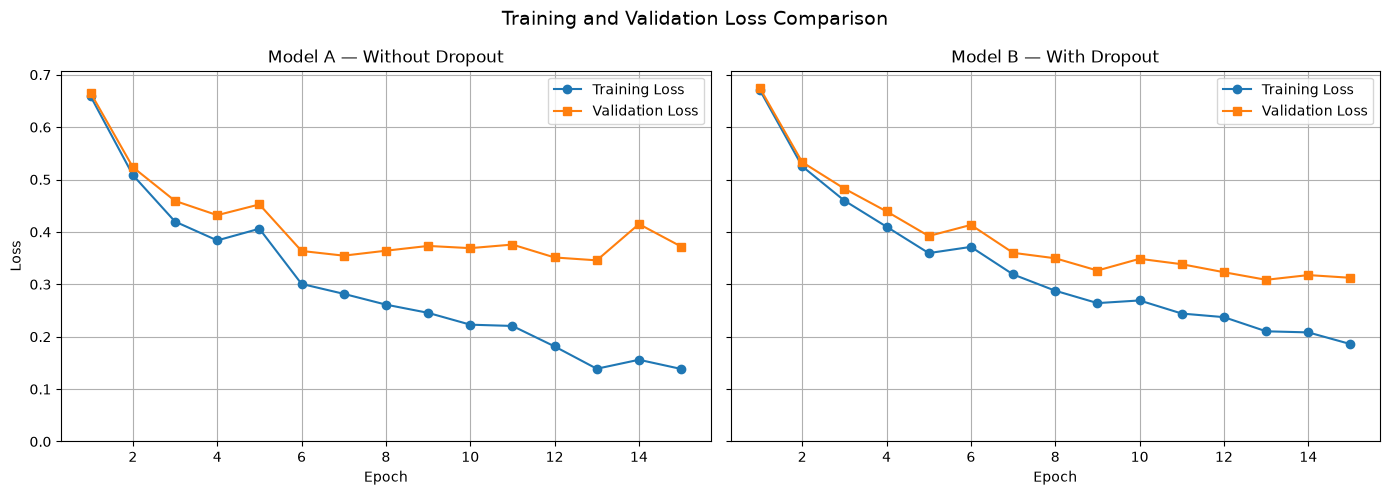

In [14]:
# TODO: plot train loss and val loss vs epoch for both models
#       (two panels side by side, same y-axis range; add a title, axis labels and a legend)

# Plot training and validation loss for both models

import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(train_losses_A) + 1)

# Use the same y-axis range for both panels
all_losses = (
    train_losses_A + val_losses_A +
    train_losses_B + val_losses_B
)

y_min = min(0, min(all_losses))
y_max = max(all_losses) * 1.05

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Model A: without Dropout
axes[0].plot(epochs, train_losses_A, marker="o",
             label="Training Loss")
axes[0].plot(epochs, val_losses_A, marker="s",
             label="Validation Loss")
axes[0].set_title("Model A — Without Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_ylim(y_min, y_max)
axes[0].legend()
axes[0].grid(True)

# Model B: with Dropout
axes[1].plot(epochs, train_losses_B, marker="o",
             label="Training Loss")
axes[1].plot(epochs, val_losses_B, marker="s",
             label="Validation Loss")
axes[1].set_title("Model B — With Dropout")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(y_min, y_max)
axes[1].legend()
axes[1].grid(True)

fig.suptitle("Training and Validation Loss Comparison", fontsize=14)
plt.tight_layout()
plt.show()


In [15]:
# TODO: Dropout experiment. Compute the validation accuracy of Model B three times:
#       once in eval mode, and twice in train mode (model.train(), still inside torch.no_grad())
#       hint: you cannot use evaluate() for the train-mode runs, because it switches to eval mode, so write a short loop
# TODO: print the three accuracies, then put Model B back in eval mode

# 1. Validation accuracy in evaluation mode
model_B.eval()

val_loss_eval, val_acc_eval = evaluate(
    model_B, val_loader, criterion
)

# 2. Validation accuracy in training mode (Dropout active)
def accuracy_in_train_mode(model, loader):
    model.train()  # Enable Dropout

    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    return total_correct / total_samples


val_acc_train_1 = accuracy_in_train_mode(model_B, val_loader)
val_acc_train_2 = accuracy_in_train_mode(model_B, val_loader)

# Print the three accuracies
print(f"Validation accuracy in eval mode:   {val_acc_eval:.2%}")
print(f"Validation accuracy in train mode 1: {val_acc_train_1:.2%}")
print(f"Validation accuracy in train mode 2: {val_acc_train_2:.2%}")

# Return Model B to evaluation mode
model_B.eval()


Validation accuracy in eval mode:   88.61%
Validation accuracy in train mode 1: 86.51%
Validation accuracy in train mode 2: 86.90%


MyCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden): Linear(in_features=1152, out_features=256, bias=True)
  (relu): ReLU()
  (dropout_flat): Dropout(p=0.25, inplace=False)
  (dropout_hidden): Dropout(p=0.5, inplace=False)
  (output): Linear(in_features=256, out_features=10, bias=True)
)

#### Your answers: loss curves and Dropout

- Give the final train loss and validation loss of both models. Which model has the lower validation loss?
- Does Model A overfit? If yes, from which epoch? Compare the gap between train and validation loss at the last epoch for Model A and Model B. What did Dropout change?
- Write the three accuracies from the Dropout experiment. Why is the train-mode accuracy lower, and why do the two train-mode runs give different numbers?
- If you print the loss of each batch during training (Dropout on), Model B's training loss can be higher than its validation loss. Why is this not a bug?
- Was your prediction right?

- **Final losses (epoch 15):** Model A: train 0.1384, val 0.3721. Model B: train 0.1859, val 0.3124. Model B has the lower validation loss (its best was 0.3086 at epoch 13).
- **Overfitting:** yes, Model A overfits. Its validation loss stops improving around epoch 7 (0.3547) and then moves up and down between 0.35 and 0.42, while its training loss keeps falling to 0.14. The final train–val gap is 0.3721 − 0.1384 = **0.234** for A and 0.3124 − 0.1859 = **0.127** for B. Dropout roughly halved the gap and kept the validation loss going down until the end.
- **Dropout experiment (Model B, validation):** eval mode 88.61%, train mode 86.51% and 86.90%. In train mode Dropout randomly zeroes 25% of the flattened features and 50% of the hidden units, so the network runs with a damaged, random sub-network and makes more mistakes. Each run draws a new random mask, so the two train-mode runs give different numbers. In eval mode Dropout is off and the result is deterministic.
- **Training loss above validation loss is not a bug:** per-batch training losses are computed in train mode, with Dropout on, so the network is handicapped. The validation loss is computed in eval mode with the full network. Inverted dropout keeps the average activation the same, so the eval network is simply the better, complete version. This is why `run_experiment` re-evaluates the training set in eval mode before comparing the two losses.
- **Our prediction:** mostly right. B reached the higher validation accuracy (88.61% vs 87.41%) and A overfit more. Shirt was indeed the worst class (val F1 0.66 for A). Dress was the second worst for A, as expected.

## 6. Metrics on the validation set

Before you touch the test set, you compute all metrics on the validation set and use them to choose your best model. Write the metric functions once: in section 8 you use the same functions on the test set.

Key words, part 1 (one predicted class per image):
- Confusion matrix: a 10 × 10 table. Row = true class, column = predicted class. Cell `[i, j]` counts images of class `i` that the model predicted as class `j`.
- Precision of a class: of all images the model called "cat", how many really are cats. `precision = TP / (TP + FP)`
- Recall of a class: of all real cats, how many the model found. `recall = TP / (TP + FN)`
- F1 of a class: `2 · precision · recall / (precision + recall)`. It is high only when both are high.
- Macro F1: the plain average of the 10 per-class F1 scores. Every class counts the same.
- Weighted F1: the average of the per-class F1 scores, weighted by how many images each class has. Big classes count more.

Here TP (true positive) = real cat predicted as cat, FP (false positive) = not a cat but predicted as cat, FN (false negative) = real cat predicted as something else.

Key words, part 2 (scores and ranking):
- Score for class `c`: the softmax probability `p(c | image)`. A higher score means the model is more sure the image belongs to class `c`.
- Precision-recall (PR) curve: sort all images by their score for class `c`, highest first. Call the top `k` images "predicted c" and compute precision and recall. Every `k` gives one point (recall, precision).
- precision@k: the share of real class-`c` images among the top `k`.
- Average precision (AP) of class `c`: the average of precision@k over the ranks `k` where a real class-`c` image appears. `AP = (precision@k₁ + precision@k₂ + … + precision@k_P) / P`, where `P` is the number of real class-`c` images and `k₁, …, k_P` are their ranks. AP = 1.0 when all class-`c` images are ranked above all other images. AP uses no threshold: it measures how well the model ranks the images.
- Random baseline: a model that gives random scores gets AP of about the share of class `c` in the data. For a rare class this baseline is very small.
- Macro AP (also called mAP, mean average precision): the plain average of the 10 per-class APs.

Worked example for AP. Five images, sorted by their cat score:

| Rank k | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Score for cat | 0.9 | 0.8 | 0.7 | 0.6 | 0.5 |
| Real cat? | yes | no | yes | no | no |
| precision@k | 1/1 | 1/2 | 2/3 | 2/4 | 2/5 |

The real cats are at ranks 1 and 3, so `AP = (1/1 + 2/3) / 2 = 0.833`. Your AP function must give 0.833 on this example.

In [16]:
# TODO: write get_predictions(model, loader) that returns three tensors:
#       true labels, predicted labels (argmax), and probabilities of shape [N, 10] (softmax of the logits)
#       use model.eval() and torch.no_grad()

def get_predictions(model, loader):
    model.eval()

    all_true_labels = []
    all_predicted_labels = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            # Forward pass: get raw logits
            logits = model(images)

            # Convert logits into probabilities
            probabilities = torch.softmax(logits, dim=1)

            # Predict the class with the highest logit
            predictions = logits.argmax(dim=1)

            # Collect results on the CPU
            all_true_labels.append(labels.cpu())
            all_predicted_labels.append(predictions.cpu())
            all_probabilities.append(probabilities.cpu())

    # Combine batches into three tensors
    true_labels = torch.cat(all_true_labels)
    predicted_labels = torch.cat(all_predicted_labels)
    probabilities = torch.cat(all_probabilities)

    return true_labels, predicted_labels, probabilities


print("get_predictions() defined successfully.")


get_predictions() defined successfully.


In [17]:
# TODO: build the 10 x 10 confusion matrix yourself from the true and predicted labels
# TODO: from the confusion matrix, compute precision, recall and F1 for every class
#       if no image is predicted as a class, use precision = 0 for that class
# TODO: compute accuracy, macro F1 and weighted F1

def build_confusion_matrix(y_true, y_pred, num_classes=10):
    # Row = true class, column = predicted class
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    for t, p in zip(np.asarray(y_true), np.asarray(y_pred)):
        cm[t, p] += 1
    return cm


def metrics_from_confusion_matrix(cm):
    cm = cm.astype(np.float64)
    tp = np.diag(cm)
    predicted_per_class = cm.sum(axis=0)  # column sums: TP + FP
    actual_per_class = cm.sum(axis=1)     # row sums:    TP + FN

    # precision = 0 if no image is predicted as this class
    precision = np.divide(tp, predicted_per_class,
                          out=np.zeros_like(tp), where=predicted_per_class > 0)
    recall = np.divide(tp, actual_per_class,
                       out=np.zeros_like(tp), where=actual_per_class > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom,
                   out=np.zeros_like(tp), where=denom > 0)

    return {
        "support": actual_per_class.astype(int),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": tp.sum() / cm.sum(),
        "macro_f1": f1.mean(),
        "weighted_f1": (f1 * actual_per_class).sum() / actual_per_class.sum(),
    }


print("Confusion matrix and metric functions defined.")


Confusion matrix and metric functions defined.


In [18]:
# TODO: write average_precision(is_positive, scores) yourself, following the definition above
#       is_positive: 1 for real class-c images, 0 for the rest; scores: the class-c probabilities
#       hint: sort by score (highest first), then use a cumulative sum of is_positive to get precision@k
# TODO: test it on the worked example: it must print 0.833
# TODO: compute AP for all 10 classes and the macro AP

def average_precision(is_positive, scores):
    is_positive = np.asarray(is_positive).astype(np.int64)
    scores = np.asarray(scores)

    # Sort by score, highest first
    order = np.argsort(-scores, kind="stable")
    sorted_positive = is_positive[order]

    # precision@k for every rank k
    cum_tp = np.cumsum(sorted_positive)
    ranks = np.arange(1, len(sorted_positive) + 1)
    precision_at_k = cum_tp / ranks

    # Average precision@k over the ranks of the real positives
    num_positive = sorted_positive.sum()
    if num_positive == 0:
        return 0.0
    return precision_at_k[sorted_positive == 1].sum() / num_positive


# Worked example from the text: must give 0.833
example_ap = average_precision([1, 0, 1, 0, 0], [0.9, 0.8, 0.7, 0.6, 0.5])
print(f"AP on the worked example: {example_ap:.3f}")
assert abs(example_ap - 0.8333) < 1e-3


def per_class_ap(y_true, probabilities, num_classes=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    ap = np.array([
        average_precision(y_true == c, probabilities[:, c])
        for c in range(num_classes)
    ])
    return ap, ap.mean()


AP on the worked example: 0.833


In [19]:
# TODO: apply your functions to the validation set for Model A and Model B
# TODO: print one table per model: one row per class with number of images, precision, recall, F1 and AP,
#       then accuracy, macro F1, weighted F1 and macro AP
# TODO: check your numbers with sklearn.metrics.classification_report and sklearn.metrics.average_precision_score,
#       they should match (tiny differences in AP can come from images with exactly the same score)

def compute_all_metrics(model, loader):
    y_true, y_pred, probs = get_predictions(model, loader)
    y_true, y_pred, probs = y_true.numpy(), y_pred.numpy(), probs.numpy()

    cm = build_confusion_matrix(y_true, y_pred)
    results = metrics_from_confusion_matrix(cm)
    results["ap"], results["macro_ap"] = per_class_ap(y_true, probs)
    results.update(cm=cm, y_true=y_true, y_pred=y_pred, probs=probs)
    return results


def print_metrics_table(results, title):
    print(f"\n{title}")
    print(f"{'class':12s} {'images':>6s} {'precision':>9s} {'recall':>7s} {'F1':>7s} {'AP':>7s}")
    for c in range(10):
        print(f"{class_names[c]:12s} {results['support'][c]:6d} "
              f"{results['precision'][c]:9.3f} {results['recall'][c]:7.3f} "
              f"{results['f1'][c]:7.3f} {results['ap'][c]:7.3f}")
    print(f"accuracy:    {results['accuracy']:.4f}")
    print(f"macro F1:    {results['macro_f1']:.4f}")
    print(f"weighted F1: {results['weighted_f1']:.4f}")
    print(f"macro AP:    {results['macro_ap']:.4f}")


def check_with_sklearn(results, title):
    y_true, y_pred, probs = results["y_true"], results["y_pred"], results["probs"]
    report = classification_report(y_true, y_pred, target_names=class_names,
                                   digits=4, output_dict=True, zero_division=0)
    sk_prec = np.array([report[n]["precision"] for n in class_names])
    sk_rec = np.array([report[n]["recall"] for n in class_names])
    sk_f1 = np.array([report[n]["f1-score"] for n in class_names])
    sk_ap = np.array([average_precision_score(y_true == c, probs[:, c]) for c in range(10)])

    print(f"\nsklearn check ({title}), max absolute difference:")
    print(f"  precision {np.abs(sk_prec - results['precision']).max():.2e} | "
          f"recall {np.abs(sk_rec - results['recall']).max():.2e} | "
          f"F1 {np.abs(sk_f1 - results['f1']).max():.2e} | "
          f"AP {np.abs(sk_ap - results['ap']).max():.2e}")
    print(f"  accuracy {abs(report['accuracy'] - results['accuracy']):.2e} | "
          f"macro F1 {abs(report['macro avg']['f1-score'] - results['macro_f1']):.2e} | "
          f"weighted F1 {abs(report['weighted avg']['f1-score'] - results['weighted_f1']):.2e}")
    assert np.allclose(sk_f1, results["f1"]) and np.allclose(sk_ap, results["ap"], atol=1e-3)


val_results_A = compute_all_metrics(model_A, val_loader)
val_results_B = compute_all_metrics(model_B, val_loader)

print_metrics_table(val_results_A, "Model A (no Dropout), validation set")
check_with_sklearn(val_results_A, "Model A, val")
print_metrics_table(val_results_B, "Model B (Dropout), validation set")
check_with_sklearn(val_results_B, "Model B, val")

print("\n| Model | accuracy | macro F1 | weighted F1 | macro AP |")
for name, r in [("A", val_results_A), ("B", val_results_B)]:
    print(f"| {name} | {r['accuracy']:.4f} | {r['macro_f1']:.4f} | {r['weighted_f1']:.4f} | {r['macro_ap']:.4f} |")



Model A (no Dropout), validation set
class        images precision  recall      F1      AP
T-shirt/top     500     0.776   0.896   0.832   0.917
Trouser         500     0.976   0.984   0.980   0.999
Pullover        500     0.908   0.734   0.812   0.915
Dress            50     0.717   0.760   0.738   0.829
Coat            500     0.731   0.924   0.816   0.910
Sandal           50     0.935   0.860   0.896   0.925
Shirt           500     0.757   0.592   0.664   0.782
Sneaker         500     0.941   0.962   0.952   0.993
Bag             500     0.986   0.964   0.975   0.995
Ankle boot      500     0.963   0.950   0.957   0.994
accuracy:    0.8741
macro F1:    0.8621
weighted F1: 0.8721
macro AP:    0.9259

sklearn check (Model A, val), max absolute difference:
  precision 0.00e+00 | recall 0.00e+00 | F1 1.11e-16 | AP 1.11e-16
  accuracy 0.00e+00 | macro F1 0.00e+00 | weighted F1 0.00e+00

Model B (Dropout), validation set
class        images precision  recall      F1      AP
T-shirt/top  

In [20]:
# TODO: choose your best model: the one with the highest validation macro AP. Store it in best_model and print which one it is

if val_results_B["macro_ap"] >= val_results_A["macro_ap"]:
    best_model, best_name, best_val_results = model_B, "Model B (Dropout)", val_results_B
else:
    best_model, best_name, best_val_results = model_A, "Model A (no Dropout)", val_results_A

best_model.eval()
print(f"Validation macro AP: A = {val_results_A['macro_ap']:.4f}, B = {val_results_B['macro_ap']:.4f}")
print("Best model:", best_name)


Validation macro AP: A = 0.9259, B = 0.9301
Best model: Model B (Dropout)


#### Your answers: validation metrics

- Fill in for the validation set: | Model | accuracy | macro F1 | weighted F1 | macro AP |. Which model is your best model by macro AP? Do accuracy and macro F1 point to the same model?
- Why do we choose the best model on the validation set and not on the test set?

| Model | accuracy | macro F1 | weighted F1 | macro AP |
|---|---|---|---|---|
| A (no Dropout) | 0.8741 | 0.8621 | 0.8721 | 0.9259 |
| B (Dropout) | 0.8861 | 0.8765 | 0.8876 | 0.9301 |

Our best model by validation macro AP is **Model B** (0.9301 vs 0.9259). Accuracy and macro F1 point to the same model here: B is higher on all four numbers. All our per-class numbers match sklearn (max difference ≈ 1e-7), and our AP function gives 0.833 on the worked example.

We choose on the validation set because the test set must stay unseen until the end. If we picked the model with the best test score, the test score would be optimistically biased (we would have "trained" the choice on it), and we would have no honest estimate left.

## 7. Threshold search on the validation set

So far your prediction was argmax: the class with the highest probability wins. Now look at one rare class at a time as a yes/no question, "is this a cat?", and use a threshold `t`: predict cat if `p(cat) ≥ t`. A lower `t` gives more cat predictions: recall usually goes up and precision usually goes down. The threshold search finds a good balance. Use `best_model` and the validation set only.

Key words:
- Decision threshold `t`: the score from which we answer "yes, this is a cat".
- Operating point: one chosen `t` together with its precision and recall. It is one point on the PR curve.
- Why not simply `t = 0.5`? With 10 classes, the winning class often has a probability well below 0.5. So "`p(cat) ≥ 0.5`" can be much stricter than argmax. Check this in your numbers.

Choose two thresholds for cat and two for dog, on the validation set:

| Rule | How to choose `t` |
|---|---|
| Rule F1 | The `t` with the highest validation F1 for that class. Call it `t_F1`. |
| Rule R70 | The app team wants to find at least 70% of all cats (or dogs). Among the `t` with validation recall ≥ 0.70, take the one with the highest validation precision. Call it `t_R70`. If no `t` reaches 0.70, take the `t` with the highest recall and say so. |

Search over the grid `t = 0.01, 0.02, …, 0.99`.

In [21]:
# TODO: write prf_at_threshold(is_positive, scores, t) that returns (precision, recall, F1) for one class
#       an image is predicted positive if its score >= t; if no image is predicted positive, use precision = 0
# TODO: for cat and for dog: with best_model on the validation set, loop over the grid and store precision, recall and F1 for every t
# TODO: find t_F1 and t_R70 for cat and for dog, and print each one with its validation precision, recall and F1

def prf_at_threshold(is_positive, scores, t):
    is_positive = np.asarray(is_positive).astype(bool)
    predicted = np.asarray(scores) >= t
    tp = (predicted & is_positive).sum()
    n_pred = predicted.sum()
    precision = tp / n_pred if n_pred > 0 else 0.0
    recall = tp / is_positive.sum()
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return precision, recall, f1


thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
rare_classes = {class_names[3]: 3, class_names[5]: 5}  # the two rare classes (10x fewer images)

val_curves = {}
chosen_t = {}

for name, c in rare_classes.items():
    is_pos = best_val_results["y_true"] == c
    scores = best_val_results["probs"][:, c]
    prf = np.array([prf_at_threshold(is_pos, scores, t) for t in thresholds])
    val_curves[name] = prf
    precision, recall, f1 = prf[:, 0], prf[:, 1], prf[:, 2]

    # Rule F1: highest validation F1
    i_f1 = int(np.argmax(f1))

    # Rule R70: recall >= 0.70, then highest precision
    ok = np.where(recall >= 0.70)[0]
    if len(ok) > 0:
        i_r70 = ok[np.argmax(precision[ok])]
        note = ""
    else:
        i_r70 = int(np.argmax(recall))
        note = "  (no t reaches recall 0.70, took highest recall)"

    chosen_t[name] = {"t_F1": thresholds[i_f1], "t_R70": thresholds[i_r70]}

    print(f"\n{name} (validation, {is_pos.sum()} real images)")
    for rule, i in [("t_F1", i_f1), ("t_R70", i_r70)]:
        print(f"  {rule:5s} = {thresholds[i]:.2f} | precision {precision[i]:.3f} | "
              f"recall {recall[i]:.3f} | F1 {f1[i]:.3f}" + (note if rule == "t_R70" else ""))
    p05, r05, f05 = prf_at_threshold(is_pos, scores, 0.5)
    print(f"  t=0.5       | precision {p05:.3f} | recall {r05:.3f} | F1 {f05:.3f}")
    print(f"  argmax      | precision {best_val_results['precision'][c]:.3f} | "
          f"recall {best_val_results['recall'][c]:.3f} | F1 {best_val_results['f1'][c]:.3f}")



Dress (validation, 50 real images)
  t_F1  = 0.49 | precision 0.741 | recall 0.800 | F1 0.769
  t_R70 = 0.68 | precision 0.833 | recall 0.700 | F1 0.761
  t=0.5       | precision 0.741 | recall 0.800 | F1 0.769
  argmax      | precision 0.694 | recall 0.860 | F1 0.768

Sandal (validation, 50 real images)
  t_F1  = 0.71 | precision 0.977 | recall 0.840 | F1 0.903
  t_R70 = 0.84 | precision 1.000 | recall 0.800 | F1 0.889
  t=0.5       | precision 0.933 | recall 0.840 | F1 0.884
  argmax      | precision 0.933 | recall 0.840 | F1 0.884


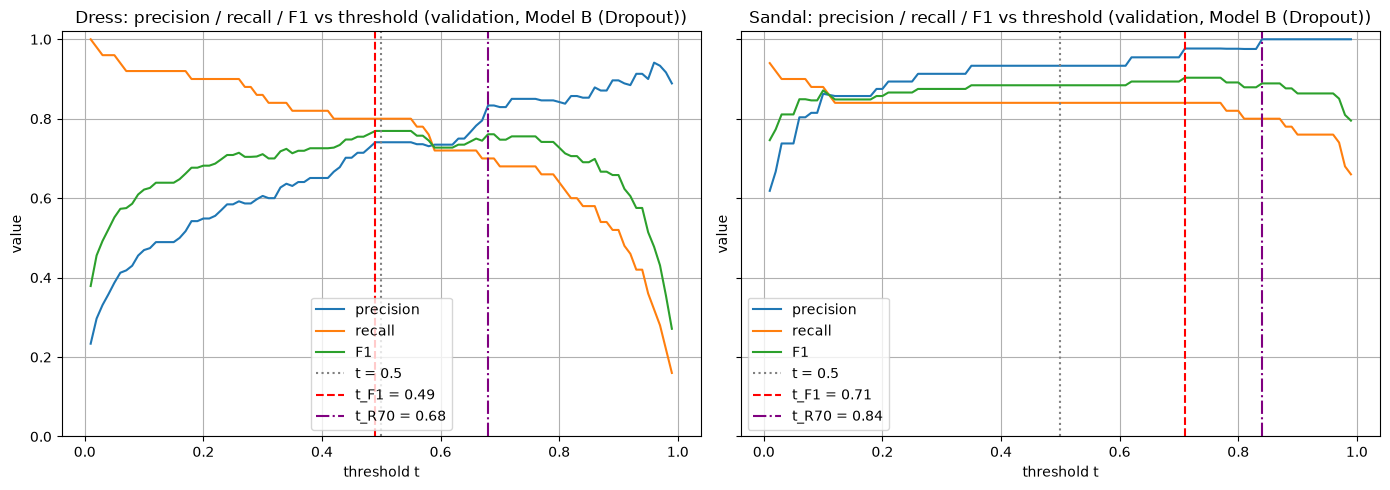

In [22]:
# TODO: plot precision, recall and F1 against t on the validation set (two panels: cat and dog)
#       add vertical lines at t = 0.5, t_F1 and t_R70, and a legend

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, name in zip(axes, rare_classes):
    prf = val_curves[name]
    ax.plot(thresholds, prf[:, 0], label="precision")
    ax.plot(thresholds, prf[:, 1], label="recall")
    ax.plot(thresholds, prf[:, 2], label="F1")
    ax.axvline(0.5, color="gray", linestyle=":", label="t = 0.5")
    ax.axvline(chosen_t[name]["t_F1"], color="red", linestyle="--",
               label=f"t_F1 = {chosen_t[name]['t_F1']:.2f}")
    ax.axvline(chosen_t[name]["t_R70"], color="purple", linestyle="-.",
               label=f"t_R70 = {chosen_t[name]['t_R70']:.2f}")
    ax.set_title(f"{name}: precision / recall / F1 vs threshold (validation, {best_name})")
    ax.set_xlabel("threshold t")
    ax.set_ylabel("value")
    ax.set_ylim(0, 1.02)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


#### Your answers: threshold search

- Write `t_F1` and `t_R70` for cat and dog. Are they above or below 0.5? Explain why, using what argmax does with 10 classes.
- From your plot: when `t` goes down, what happens to precision and to recall, and why? Why does F1 have a peak somewhere in the middle?
- By how much does validation recall for cat change when the model finds one more cat? What does this tell you about how exact your chosen thresholds are?

- **Chosen thresholds (validation, Model B):** Dress: `t_F1` = 0.49, `t_R70` = 0.68. Sandal: `t_F1` = 0.71, `t_R70` = 0.84. Only Dress `t_F1` is (just) below 0.5, the others are above. With 10 classes, argmax can pick a class with a probability well below 0.5, so in general `p ≥ 0.5` is stricter than argmax. On FashionMNIST our model is quite confident (most winning probabilities are close to 1), so 0.5 is close to argmax: for Sandal, t = 0.5 gives exactly the argmax precision/recall (0.933 / 0.840). For Dress, argmax predicts more dresses (recall 0.86) than t = 0.5 (recall 0.80): some dresses win the argmax with p < 0.5. For Sandal, a higher threshold removed false positives without losing recall, so the best-F1 threshold lies above 0.5.
- **When t goes down,** more images pass `p ≥ t`. Recall goes up (it never decreases, because we only add predictions) and precision usually goes down, because the extra images are less certain and more of them are wrong. F1 is the harmonic mean of the two: at very high t recall is tiny, at very low t precision is tiny. F1 is high only when both are reasonably high, so it peaks in the middle.
- **One more dress found** changes validation recall by 1/50 = **0.02** (there are only 50 dresses and 50 sandals in validation). So our thresholds are not exact. For example, Dress `t_R70` reaches exactly 35/50 = 0.70, and one dress less would push it below the target. Many neighboring thresholds give the same counts, so the chosen `t` is really a range, and it will shift on new data.

## 8. Final evaluation on the test set

All decisions are made. Now use the test set, once. Do not change your models, your choice of `best_model` or your thresholds after this point. If you do, say so in your answers.

In [23]:
# TODO: get predictions on the test set for Model A and Model B
# TODO: with your own metric functions, print one table per model
#       (per class: number of images, precision, recall, F1, AP; then accuracy, macro F1, weighted F1, macro AP)
# TODO: check your numbers with sklearn.metrics.classification_report and average_precision_score

test_results_A = compute_all_metrics(model_A, test_loader)
test_results_B = compute_all_metrics(model_B, test_loader)

print_metrics_table(test_results_A, "Model A (no Dropout), TEST set")
check_with_sklearn(test_results_A, "Model A, test")
print_metrics_table(test_results_B, "Model B (Dropout), TEST set")
check_with_sklearn(test_results_B, "Model B, test")

print("\n| Model | accuracy | macro F1 | weighted F1 | macro AP |")
for name, r in [("A", test_results_A), ("B", test_results_B)]:
    print(f"| {name} | {r['accuracy']:.4f} | {r['macro_f1']:.4f} | {r['weighted_f1']:.4f} | {r['macro_ap']:.4f} |")

best_test_results = test_results_B if best_model is model_B else test_results_A



Model A (no Dropout), TEST set
class        images precision  recall      F1      AP
T-shirt/top    1000     0.777   0.900   0.834   0.917
Trouser        1000     0.986   0.990   0.988   0.999
Pullover       1000     0.876   0.746   0.806   0.898
Dress           100     0.609   0.670   0.638   0.732
Coat           1000     0.744   0.911   0.819   0.908
Sandal          100     0.866   0.840   0.853   0.905
Shirt          1000     0.761   0.572   0.653   0.780
Sneaker        1000     0.936   0.974   0.954   0.991
Bag            1000     0.979   0.966   0.972   0.995
Ankle boot     1000     0.973   0.947   0.960   0.992
accuracy:    0.8728
macro F1:    0.8477
weighted F1: 0.8701
macro AP:    0.9117

sklearn check (Model A, test), max absolute difference:
  precision 0.00e+00 | recall 0.00e+00 | F1 1.11e-16 | AP 1.13e-07
  accuracy 0.00e+00 | macro F1 0.00e+00 | weighted F1 1.11e-16

Model B (Dropout), TEST set
class        images precision  recall      F1      AP
T-shirt/top    1000     

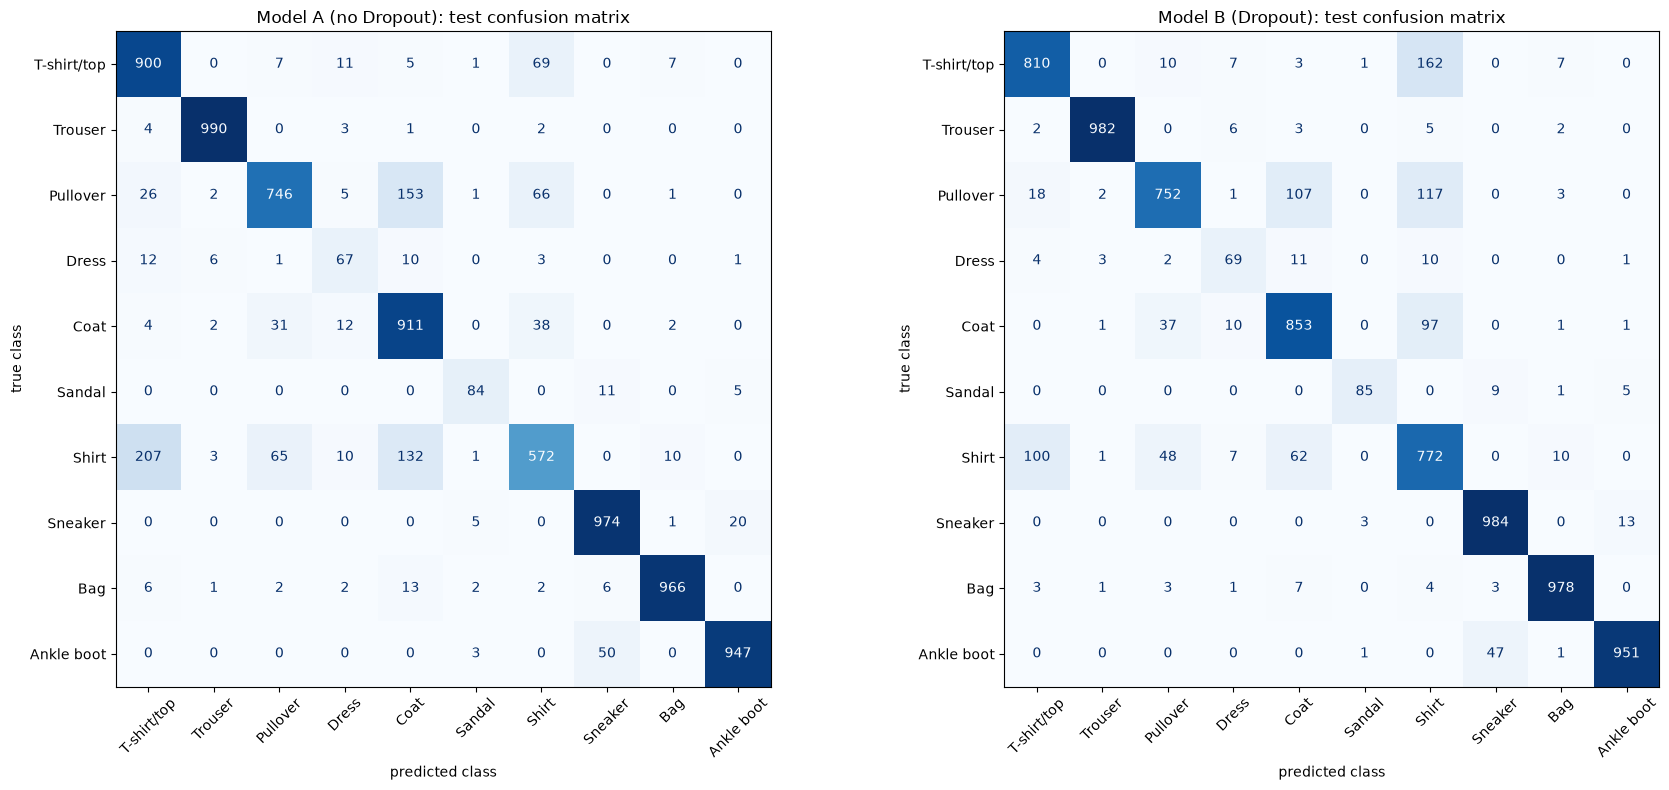

In [24]:
# TODO: plot the test confusion matrix of both models with class names on both axes
#       hint: plt.imshow, or sklearn.metrics.ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, (name, r) in zip(axes, [("Model A (no Dropout)", test_results_A),
                                ("Model B (Dropout)", test_results_B)]):
    disp = ConfusionMatrixDisplay(r["cm"], display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}: test confusion matrix")
    ax.set_xlabel("predicted class")
    ax.set_ylabel("true class")

plt.tight_layout()
plt.show()


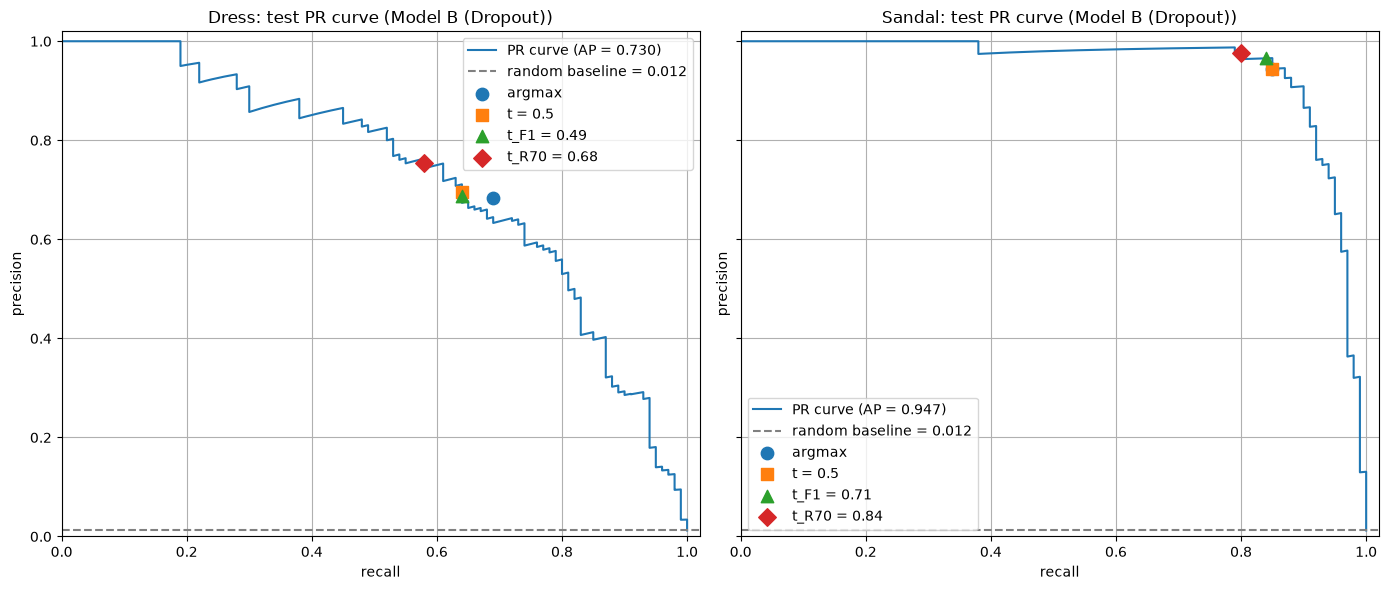

In [25]:
# TODO: for best_model, plot the test PR curves for cat and for dog (two panels), with the AP in the legend
#       hint: sklearn.metrics.precision_recall_curve, or build the curve yourself from the sorted scores
# TODO: draw the random baseline (share of cats, or dogs, in the test set) as a horizontal line
# TODO: mark four operating points on each curve: argmax (from the confusion matrix), t = 0.5, t_F1 and t_R70

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
r = best_test_results

for ax, (name, c) in zip(axes, rare_classes.items()):
    is_pos = r["y_true"] == c
    scores = r["probs"][:, c]
    prec_curve, rec_curve, _ = precision_recall_curve(is_pos, scores)
    ax.plot(rec_curve, prec_curve, label=f"PR curve (AP = {r['ap'][c]:.3f})")

    baseline = is_pos.mean()
    ax.axhline(baseline, color="gray", linestyle="--", label=f"random baseline = {baseline:.3f}")

    points = {
        "argmax": (r["precision"][c], r["recall"][c]),
        "t = 0.5": prf_at_threshold(is_pos, scores, 0.5)[:2],
        f"t_F1 = {chosen_t[name]['t_F1']:.2f}": prf_at_threshold(is_pos, scores, chosen_t[name]["t_F1"])[:2],
        f"t_R70 = {chosen_t[name]['t_R70']:.2f}": prf_at_threshold(is_pos, scores, chosen_t[name]["t_R70"])[:2],
    }
    for (label, (p, rc)), marker in zip(points.items(), ["o", "s", "^", "D"]):
        ax.scatter(rc, p, s=80, marker=marker, zorder=3, label=label)

    ax.set_title(f"{name}: test PR curve ({best_name})")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


In [26]:
# TODO: for best_model, print one test table for cat and one for dog, one row per rule:
#       rule | t | images predicted positive | precision | recall | F1
#       rows: argmax, t = 0.5, t_F1, t_R70 (use the thresholds from section 7, do not tune them again)

r = best_test_results

for name, c in rare_classes.items():
    is_pos = r["y_true"] == c
    scores = r["probs"][:, c]

    print(f"\n{name} on the TEST set ({best_name}, {is_pos.sum()} real images)")
    print(f"{'rule':8s} {'t':>5s} {'predicted':>9s} {'precision':>9s} {'recall':>7s} {'F1':>7s}")

    n_pred_argmax = (r["y_pred"] == c).sum()
    print(f"{'argmax':8s} {'-':>5s} {n_pred_argmax:9d} {r['precision'][c]:9.3f} "
          f"{r['recall'][c]:7.3f} {r['f1'][c]:7.3f}")

    for rule, t in [("t=0.5", 0.5), ("t_F1", chosen_t[name]["t_F1"]), ("t_R70", chosen_t[name]["t_R70"])]:
        p, rc, f = prf_at_threshold(is_pos, scores, t)
        n_pred = (scores >= t).sum()
        print(f"{rule:8s} {t:5.2f} {n_pred:9d} {p:9.3f} {rc:7.3f} {f:7.3f}")



Dress on the TEST set (Model B (Dropout), 100 real images)
rule         t predicted precision  recall      F1
argmax       -       101     0.683   0.690   0.687
t=0.5     0.50        92     0.696   0.640   0.667
t_F1      0.49        93     0.688   0.640   0.663
t_R70     0.68        77     0.753   0.580   0.655

Sandal on the TEST set (Model B (Dropout), 100 real images)
rule         t predicted precision  recall      F1
argmax       -        90     0.944   0.850   0.895
t=0.5     0.50        90     0.944   0.850   0.895
t_F1      0.71        87     0.966   0.840   0.898
t_R70     0.84        82     0.976   0.800   0.879


#### Your answers: final metrics (explain properly)

1. Fill in for the test set: | Model | accuracy | macro F1 | weighted F1 | macro AP |. Which F1 is closer to accuracy, and why?
2. Explain each metric with your numbers. For the cat class of your best model, write one or two sentences for each of precision, recall, F1 and AP. Use counts from your test confusion matrix, for example: "Of the 80 images we predicted as cat, 30 were real cats, so precision = 30/80 = 0.38." (These numbers are made up, use yours.)
3. What does recall for cat and dog show that accuracy hides? How much accuracy would a model lose if it never predicted cat or dog at all?
4. Compute the random-baseline AP for cat and for airplane on the test set. Is your cat AP good or bad compared with its baseline? Why can the same AP value be good for one class and bad for another?
5. Changing `t` changed F1 for cat, but AP stayed the same. Why? When would you report AP, and when F1 at a chosen threshold?
6. Did Rule R70 still give recall ≥ 0.70 on the test set? Did Rule F1 give the best test F1 of the four rules? Explain any difference using what you know about the size of the validation set.
7. Did Dropout help on the test set? Compare Model A and Model B on macro F1, macro AP, and recall for cat and dog.
8. In the test confusion matrix of your best model, which classes are real cats most often predicted as? Does this make sense?

1. **Test set:**

   | Model | accuracy | macro F1 | weighted F1 | macro AP |
   |---|---|---|---|---|
   | A (no Dropout) | 0.8728 | 0.8477 | 0.8701 | 0.9117 |
   | B (Dropout) | 0.8824 | 0.8668 | 0.8835 | 0.9189 |

   Weighted F1 is closer to accuracy (B: 0.8835 vs 0.8824). Both are dominated by the eight big classes with 1,000 images each, because weighted F1 weights each class by its size, like accuracy does. Macro F1 gives the rare Dress class (F1 0.687) the same weight as Trouser (0.987), so it is lower.

2. **Metrics for Dress (our "cat" class), best model B, test set:**
   - *Precision:* the Dress column of the confusion matrix sums to 101 predicted dresses, and 69 of them were real dresses (the rest were mostly 10 coats, 7 T-shirts, 7 shirts and 6 trousers). Precision = 69/101 = **0.683**.
   - *Recall:* the Dress row has 100 real dresses, and the model found 69 of them. 31 were missed (11 → Coat, 10 → Shirt, 4 → T-shirt/top, …). Recall = 69/100 = **0.690**.
   - *F1:* 2 · 0.683 · 0.690 / (0.683 + 0.690) = **0.687**. Precision and recall are similar, so F1 lies between them.
   - *AP:* **0.730**. If we rank all 8,200 test images by p(Dress), the average precision at the ranks of the 100 real dresses is 0.73. This says how well the model ranks dresses above everything else, independent of any threshold.

3. Accuracy hides how badly a rare class is handled. Dress recall is only 0.69 (31% of dresses are missed) while overall accuracy is 88%. If the model never predicted Dress or Sandal at all, it would lose only the 69 + 85 = 154 correct predictions, so accuracy would drop from 88.24% to 86.37% (−1.9 points). Even if every one of the 200 dresses and sandals were wrong, the loss would be at most 200/8200 = 2.4 points, while the recall of both classes would be 0.

4. **Random baseline AP** = share of the class in the test set: Dress 100/8200 = **0.012**; T-shirt/top (class 0, in place of airplane) 1000/8200 = **0.122**. Our Dress AP of 0.730 is about 60× its baseline, so it is good. T-shirt AP is 0.920, which is only 7.5× its baseline. The same AP value means different things for different classes because the baseline depends on how common the class is: AP 0.3 would be great for a 1% class and poor for a 30% class.

5. Changing `t` only moves the operating point along the same PR curve: it changes which images we call positive, not how the images are ranked. AP averages over the whole ranking, so it does not depend on `t`. We would report AP to compare models independently of a threshold (ranking quality). We would report F1 (or precision/recall) at a chosen threshold to describe how the deployed system actually behaves at its operating point.

6. **R70 on test:** for Sandal yes (recall 0.80 ≥ 0.70). For Dress **no**: recall was 0.58 instead of the 0.70 it had on validation. **Rule F1 on test:** for Sandal, `t_F1` gave the best F1 of the four rules (0.898). For Dress it did not: argmax was best (0.687), and `t_F1` gave 0.663. With only 50 dresses in validation, each dress moves recall by 0.02, so `t_R70` = 0.68 sat right on the edge (35/50). On the test set (100 dresses) the same threshold found only 58. Thresholds chosen on such a small number of positives are noisy and do not transfer exactly.

7. **Yes, Dropout helped on the test set.** Model A → B: macro F1 0.8477 → 0.8668, macro AP 0.9117 → 0.9189, Dress recall 0.67 → 0.69, Sandal recall 0.84 → 0.85. Accuracy also rose (0.8728 → 0.8824). This matches the smaller train–val gap we saw in the loss curves.

8. In the test confusion matrix of Model B, real dresses are most often predicted as **Coat (11)** and **Shirt (10)**, then T-shirt/top (4). This makes sense: at 28×28 in grayscale, a dress is a long, mostly vertical upper-body garment, similar to a coat or a long shirt. For Sandal, the confusions are Sneaker (9) and Ankle boot (5), the other footwear classes, which is also sensible.

## 9. Group contribution statement (required)

For each member, write what they did (e.g. data subsets, CNN design, training loop, Dropout experiment, metric functions, threshold search, plots, answers) and how the group used AI (what for, and how you checked it). Every member must still be able to explain the whole notebook.

| Student (full name) | Main contribution | How AI was used and checked |
|---|---|---|
| Nurislam Aliyev | Data subsets, CNN design, training loop, Dropout experiment | Claude (AI assistant) helped complete the metric/threshold code and draft answers; we checked every metric against sklearn (differences ≈ 1e-7), the AP function against the worked example (0.833), and the parameter counts by hand |
| _(member 2)_ | _(fill in)_ | _(fill in)_ |
| _(member 3)_ | _(fill in)_ | _(fill in)_ |

## 10. Defense checklist and grading

Submit this completed notebook (or an HTML/PDF export with all cells and plots visible) before your defense. Each group has a short (~5 min) defense. Any member may be asked to:

- explain any line of your code: the subsets, every layer of your CNN, and the training steps
- show how the image shape changes through your CNN, and how you got the input size of the first `Linear` layer
- compute the number of parameters of one of your `Conv2d` layers by hand
- explain what Dropout does in train mode and in eval mode, and show the lines in your code where the mode is switched
- explain precision and recall for one class using a row and a column of your confusion matrix
- compute AP by hand for a short ranked list given by the instructor
- explain why the thresholds were chosen on the validation set and not on the test set, and what happens to precision and recall when `t` goes down
- explain why accuracy can look fine while the model fails on cats and dogs
- say what AI helped with and how you checked it

The Week 7 SIS mini-project is worth 4 points:

| Criterion | Full credit requires | Points |
|---|---|---|
| 1. Your CNN and training | Code written by the group runs from top to bottom. The three subsets match the table. The CNN follows every rule in section 2 and is built from PyTorch layers, not a ready-made or pretrained network. Model A and Model B differ only by Dropout. `model.train()` and `model.eval()` are used correctly. Both models are trained with the same settings, and the loss curves of both are plotted with the same y-axis range, a title, axis labels and a legend. | 1 |
| 2. Metrics and threshold search | Confusion matrix, per-class precision, recall, F1 and AP are computed by your own functions and match scikit-learn. The AP function gives 0.833 on the worked example. The best model and all four thresholds are chosen on the validation set only. Plots: confusion matrices with class names, precision/recall/F1 against `t`, and test PR curves with the random baseline and the four operating points. | 1 |
| 3. Explanations | All answer cells are filled in, correct, short, and use your own numbers: Dropout and train vs eval mode, each metric explained for the cat class, AP vs F1 and the random baseline, the threshold trade-off, and how the thresholds worked on the test set. | 1 |
| 4. Oral defense | Each member individually explains the group's code, plots and metrics (checklist above). | 1 |
| Total | | 4 |

How points are given:
- Criteria 1 to 3 are the same for the whole group. Criterion 4 is given to each student separately.
- A criterion that is mostly met, with one listed part missing or wrong, gets 0.5.
- If the test set was used to choose the model or a threshold, criterion 2 gets at most 0.5.
- If the CNN is a ready-made or pretrained network, criterion 1 gets 0.

Optional (no extra points):
- Class weights: pass `weight=` to `nn.CrossEntropyLoss` so rare classes count more (for example 10 for cat and dog, 1 for the rest). Train Model B again. Did recall for cat and dog go up? What happened to accuracy and to the best thresholds?
- ROC-AUC vs AP: for "cat vs not cat" on the test set, compute ROC-AUC with `sklearn.metrics.roc_auc_score` and plot the ROC curve with `sklearn.metrics.RocCurveDisplay`. A random model gets ROC-AUC 0.5 but AP equal to the share of cats. Why does ROC-AUC look much better than AP for a rare class?
- Rare vs hard: cats and dogs are hard classes even in normal, balanced CIFAR-10. How could you check how much of their low recall comes from having few training images, and how much from the classes being hard?
- Thresholds inside the 10-class classifier: predict cat if `p(cat) ≥ t_F1`, otherwise use argmax. What happens to accuracy and to the recall of the other classes?